In [ ]:
# 1. Mount your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Set up Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 3. Download the zip file to the temporary Colab storage (this is faster)
!kaggle datasets download -d khanfashee/nih-chest-x-ray-14-224x224-resized

# 4. Unzip the dataset directly into your Google Drive for permanent storage
!mkdir -p "/content/drive/MyDrive/Medical_Imaging_Project/nih_dataset"
!unzip -q nih-chest-x-ray-14-224x224-resized.zip -d "/content/drive/MyDrive/Medical_Imaging_Project/nih_dataset"


Mounted at /content/drive
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
License(s): CC0-1.0
100% 2.30G/2.30G [00:18<00:00, 131MB/s]



In [ ]:
!pip install -q monai pydicom grad-cam kaggle

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

# Set up Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 1. Download the zip to local Colab storage (Fast)
!kaggle datasets download -d khanfashee/nih-chest-x-ray-14-224x224-resized -p /content/

# 2. Copy the single ZIP file to Google Drive for permanent backup (Fast - just one file)
zip_backup_dir = "/content/drive/MyDrive/Medical_Imaging_Project/dataset_backup"
os.makedirs(zip_backup_dir, exist_ok=True)
!cp /content/nih-chest-x-ray-14-224x224-resized.zip {zip_backup_dir}/

# 3. Unzip the dataset into Colab's local high-speed storage (Fast)
!unzip -q /content/nih-chest-x-ray-14-224x224-resized.zip -d /content/nih_dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
License(s): CC0-1.0
100% 2.30G/2.30G [00:19<00:00, 124MB/s]



In [ ]:
import os
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Back up the already-downloaded zip file to your Google Drive
zip_backup_dir = "/content/drive/MyDrive/Medical_Imaging_Project/dataset_backup"
os.makedirs(zip_backup_dir, exist_ok=True)
!cp /content/nih-chest-x-ray-14-224x224-resized.zip {zip_backup_dir}/

# 3. Unzip the dataset into Colab's fast local storage
!unzip -q /content/nih-chest-x-ray-14-224x224-resized.zip -d /content/nih_dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/nih_dataset/BBox_List_2017_Official_NIH.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
!unzip -q -o /content/nih-chest-x-ray-14-224x224-resized.zip -d /content/nih_dataset

In [ ]:
import os
import glob
import pandas as pd
import torch
import torch.nn as nn
import monai
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    RandRotated, RandFlipd, ToTensord, Lambdad
)
from monai.data import Dataset, DataLoader
from monai.networks.nets import DenseNet121

# 1. Setup Paths and Device
dataset_dir = '/content/nih_dataset'
csv_path = os.path.join(dataset_dir, 'Data_Entry_2017.csv')

# Programmatically find the actual folder containing the images
image_search = glob.glob(os.path.join(dataset_dir, '**/*.png'), recursive=True)
if not image_search:
    raise FileNotFoundError(f"No .png images found anywhere in {dataset_dir}. Please verify unzip step.")

# Use the directory containing the first found PNG image
images_dir = os.path.dirname(image_search[0])
print(f"Dynamically detected images directory: {images_dir}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")
if device.type == "cpu":
    print("\n[WARNING]: Running on CPU. Training will be extremely slow. Go to 'Runtime' -> 'Change runtime type' -> Select 'T4 GPU' for fast training.\n")

# 2. Parse the CSV and Prepare Labels
print("Loading dataset metadata...")
df = pd.read_csv(csv_path)

# For this demo, we will do binary classification: 'Pneumonia' vs 'Other/No Finding'
# Filter to a subset (e.g., 5000 images) to test the pipeline quickly before full training
df_subset = df.head(5000).copy()

image_paths = [os.path.join(images_dir, img) for img in df_subset['Image Index']]
labels = [1 if 'Pneumonia' in label else 0 for label in df_subset['Finding Labels']]

# Ensure all mapped paths actually exist before building dataset
valid_data_dicts = []
for img, lbl in zip(image_paths, labels):
    if os.path.exists(img):
        valid_data_dicts.append({'image': img, 'label': lbl})
    else:
        # Some images might be in other parts/subfolders, let's search if not in default found path
        fallback_path = glob.glob(os.path.join(dataset_dir, f"**/{os.path.basename(img)}"), recursive=True)
        if fallback_path:
            valid_data_dicts.append({'image': fallback_path[0], 'label': lbl})

print(f"Total items mapped to existing files: {len(valid_data_dicts)} / {len(df_subset)}")
if not valid_data_dicts:
    raise FileNotFoundError("None of the images specified in the CSV head could be matched to existing files.")

# Helper function to ensure images consistently have only 1 channel (grayscale)
def ensure_single_channel(image_tensor):
    if image_tensor.shape[0] > 1:
        # Take the mean across the channels or slice the first channel to get grayscale
        return image_tensor[0:1, ...]
    return image_tensor

# 3. Define Preprocessing and Augmentation Transforms
train_transforms = Compose([
    LoadImaged(keys=['image'], image_only=True),
    EnsureChannelFirstd(keys=['image']),
    # Convert any multi-channel images (e.g. RGB) to single-channel (grayscale)
    Lambdad(keys=['image'], func=ensure_single_channel),
    ScaleIntensityd(keys=['image']),
    RandRotated(keys=['image'], range_x=0.1, prob=0.5),
    RandFlipd(keys=['image'], spatial_axis=0, prob=0.5),
    ToTensord(keys=['image', 'label'])
])

# 4. Create MONAI Dataset and DataLoader
print("Initializing DataLoader...")
train_ds = Dataset(data=valid_data_dicts, transform=train_transforms)
# Reduce num_workers on CPU to avoid overhead bottlenecks
num_workers = 2 if device.type == "cuda" else 0
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=num_workers)

# 5. Initialize DenseNet121 Model
print("Loading DenseNet121...")
model = DenseNet121(spatial_dims=2, in_channels=1, out_channels=2).to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# 6. Training Loop
epochs = 5 # Set low for initial pipeline testing
print("Starting training loop...")

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    step = 0

    for batch_data in train_loader:
        step += 1
        inputs, batch_labels = batch_data['image'].to(device), batch_data['label'].to(device)

        optimizer.zero_grad()
        outputs = model(inputs)

        loss = loss_function(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        if step % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Step {step}/{len(train_loader)}, Batch Loss: {loss.item():.4f}")

    avg_loss = epoch_loss / len(train_loader)
    print(f"--- Epoch {epoch+1} Completed. Average Loss: {avg_loss:.4f} ---")

print("Training pipeline test complete!")

# 7. Save the model weights to your Drive for the deployment phase
model_save_path = '/content/drive/MyDrive/Medical_Imaging_Project/densenet_model_v1.pth'
torch.save(model.state_dict(), model_save_path)
print(f"Model saved to {model_save_path}")

Dynamically detected images directory: /content/nih_dataset/images-224/images-224
Training on device: cuda
Loading dataset metadata...
Total items mapped to existing files: 5000 / 5000
Initializing DataLoader...
Loading DenseNet121...
Starting training loop...
Epoch 1/5, Step 10/157, Batch Loss: 0.2356
Epoch 1/5, Step 20/157, Batch Loss: 0.0752
Epoch 1/5, Step 30/157, Batch Loss: 0.2424
Epoch 1/5, Step 40/157, Batch Loss: 0.0340
Epoch 1/5, Step 50/157, Batch Loss: 0.2557
Epoch 1/5, Step 60/157, Batch Loss: 0.0420
Epoch 1/5, Step 70/157, Batch Loss: 0.1385
Epoch 1/5, Step 80/157, Batch Loss: 0.0233
Epoch 1/5, Step 90/157, Batch Loss: 0.1396
Epoch 1/5, Step 100/157, Batch Loss: 0.0241
Epoch 1/5, Step 110/157, Batch Loss: 0.0215
Epoch 1/5, Step 120/157, Batch Loss: 0.1294
Epoch 1/5, Step 130/157, Batch Loss: 0.0214
Epoch 1/5, Step 140/157, Batch Loss: 0.0155
Epoch 1/5, Step 150/157, Batch Loss: 0.0131
--- Epoch 1 Completed. Average Loss: 0.1069 ---
Epoch 2/5, Step 10/157, Batch Loss: 0.01

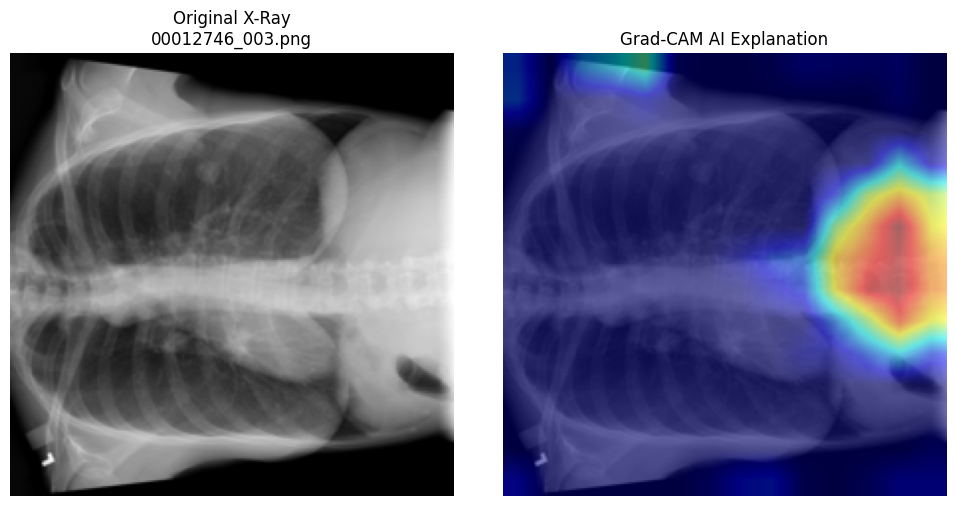

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from monai.networks.nets import DenseNet121
from monai.transforms import LoadImage, EnsureChannelFirst, ScaleIntensity, Compose, ToTensor
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize model and load your saved weights
model_save_path = '/content/drive/MyDrive/Medical_Imaging_Project/densenet_model_v1.pth'
model = DenseNet121(spatial_dims=2, in_channels=1, out_channels=2).to(device)
model.load_state_dict(torch.load(model_save_path, map_location=device))
model.eval()

# 2. Pick a random test image from your dynamically resolved unzipped dataset
if 'images_dir' not in locals() or not os.path.exists(images_dir):
    images_dir = '/content/nih_dataset/images-224/images-224'

test_image_filename = os.listdir(images_dir)[0]
test_image_path = os.path.join(images_dir, test_image_filename)

# 3. Preprocess the image exactly as we did for training
val_transforms = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    ScaleIntensity(),
    ToTensor()
])

input_tensor = val_transforms(test_image_path).unsqueeze(0).to(device)  # Add batch dimension

# Ensure single channel grayscale
if input_tensor.shape[1] > 1:
    input_tensor = input_tensor[:, 0:1, ...]

# Enable gradient tracking on the input for Grad-CAM
input_tensor.requires_grad = True

# 4. Configure Grad-CAM
# Target the last convolutional layer of DenseNet121 for valid gradient retrieval
target_layers = [model.features.transition3.conv]
cam = GradCAM(model=model, target_layers=target_layers)

# Target class 1 (Pneumonia/Disease) to see what features indicate disease
targets = [ClassifierOutputTarget(1)]

# 5. Generate Heatmap (wrapped in enable_grad to ensure gradients are computed)
with torch.enable_grad():
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

# 6. Visualize: Overlay heatmap on the original image
original_img = input_tensor.detach().squeeze().cpu().numpy()
rgb_img = np.stack((original_img,)*3, axis=-1)

visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original_img, cmap='gray')
axes[0].set_title(f"Original X-Ray\n{test_image_filename}")
axes[0].axis('off')

axes[1].imshow(visualization)
axes[1].set_title("Grad-CAM AI Explanation")
axes[1].axis('off')

plt.tight_layout()
plt.show()